# v9c: lesion DURING normal continual training, 30% switched off (GPU 0)
Same as `nextphase_v9.ipynb`, but **30%** of each layer's working neurons are switched off instead of 10%.
Results: `analysis/v9/nextphase_d30/`. Start checkpoints: distant 30, 40; related 10, 15. Conditions: nothing / self / look-alike / random.
Seed 0 of everything first. Re-running skips what is done.

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "0"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def last_phase(run):
    phs = [int(os.path.basename(f)[1:4]) for f in FILES if f.startswith(f"{run}/ckpt/p")]
    phs += [int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{run}/ckpt/p*.pt")]
    return max(phs)

def run(langset, *cmd):
    env = {**os.environ, "CML_LANGSET": langset}
    p = subprocess.Popen([sys.executable, "-u", "newtask_v9.py", "--gpu", GPU, "--tasks", "next", "--out", "nextphase_d30", "--dose", "0.30", *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

DIST, REL = "v4b_continual_s0", "v8_indic_continual_s0"
STARTS = [("distant", DIST, 30), ("distant", DIST, 40), ("indic", REL, 10), ("indic", REL, 15)]
for _, r, ph in STARTS:
    get(r, [ph])
print("start models:", [(r, ph) for _, r, ph in STARTS])

p030_ar.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p040_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p010_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p015_pa.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

start models: [('v4b_continual_s0', 30), ('v4b_continual_s0', 40), ('v8_indic_continual_s0', 10), ('v8_indic_continual_s0', 15)]


In [2]:
need = [f"data/en-{l}/train.jsonl" for l in ["hi", "zh", "gu"]] + [f"data/flores/devtest.{l}.jsonl" for l in ["en", "hi", "zh", "gu"]]
need += [f"data/flores/dev.{l}.jsonl" for l in ["en", "hi", "zh", "ar", "gu", "pa"]] + [f"data/en-{l}/val.jsonl" for l in ["hi", "zh", "ar", "gu", "pa"]]
miss = [f for f in need if not os.path.exists(f)]
print("all there" if not miss else f"MISSING: {miss}  -> run your download snippet first, then re-run this cell")

all there


In [3]:
for s in ["0", "1", "2"]:
    for langset, r, ph in STARTS:
        run(langset, "--start", f"{'distant' if langset == 'distant' else 'related'}{ph}={r}:{ph}", "--seeds", s)
    subprocess.run([sys.executable, "newtask_v9.py", "--summarize", "--out", "nextphase_d30"])

start model: distant30 = v4b_continual_s0 phase 30 (last trained on ar) | language set distant: hi, zh, ar
  enc0.mlp: 2560 working neurons, self = 1234 (48%), switching off 768
  enc1.mlp: 2560 working neurons, self = 1189 (46%), switching off 768
  enc2.mlp: 2560 working neurons, self = 1224 (48%), switching off 768
  enc3.mlp: 2560 working neurons, self = 1538 (60%), switching off 768
  dec0.mlp: 2560 working neurons, self = 1482 (58%), switching off 768
  dec1.mlp: 2560 working neurons, self = 1325 (52%), switching off 768
  dec2.mlp: 2560 working neurons, self = 1394 (54%), switching off 768
  dec3.mlp: 2560 working neurons, self = 2049 (80%), switching off 768
  self found in 6s
  'next' task for this start model = hi (phase 31 of the normal schedule)
runs to do in this call: 4 (1 tasks x 4 conditions x seeds [0]; already done are skipped)
    dec3.mlp: self or task group too small, layer left intact
  loaded next: 300,000 train examples
  distant30 | next       | none      | see

=== v9: learning a NEW task with part of the self switched off ===
one comparison = one start model x one seed x one task: self switched off vs look-alike task neurons switched off
learning slowness = average held-out loss over the learning curve (steps 50 ... end); lower = learned faster

AVERAGE OVER SEEDS (curve loss | final score; score = accuracy % or chrF for Indonesian)
                          curve_loss  final_score  seeds
task start     cond                                     
next distant30 lookalike       2.199       47.459      3
               none            2.051       47.840      3
               random          2.197       47.425      3
               self            2.237       47.177      3
     distant40 lookalike       2.661       22.972      3
               none            2.557       24.122      3
               random          2.650       22.996      3
               self            2.716       22.990      3
     related10 lookalike       2.439       42.006 

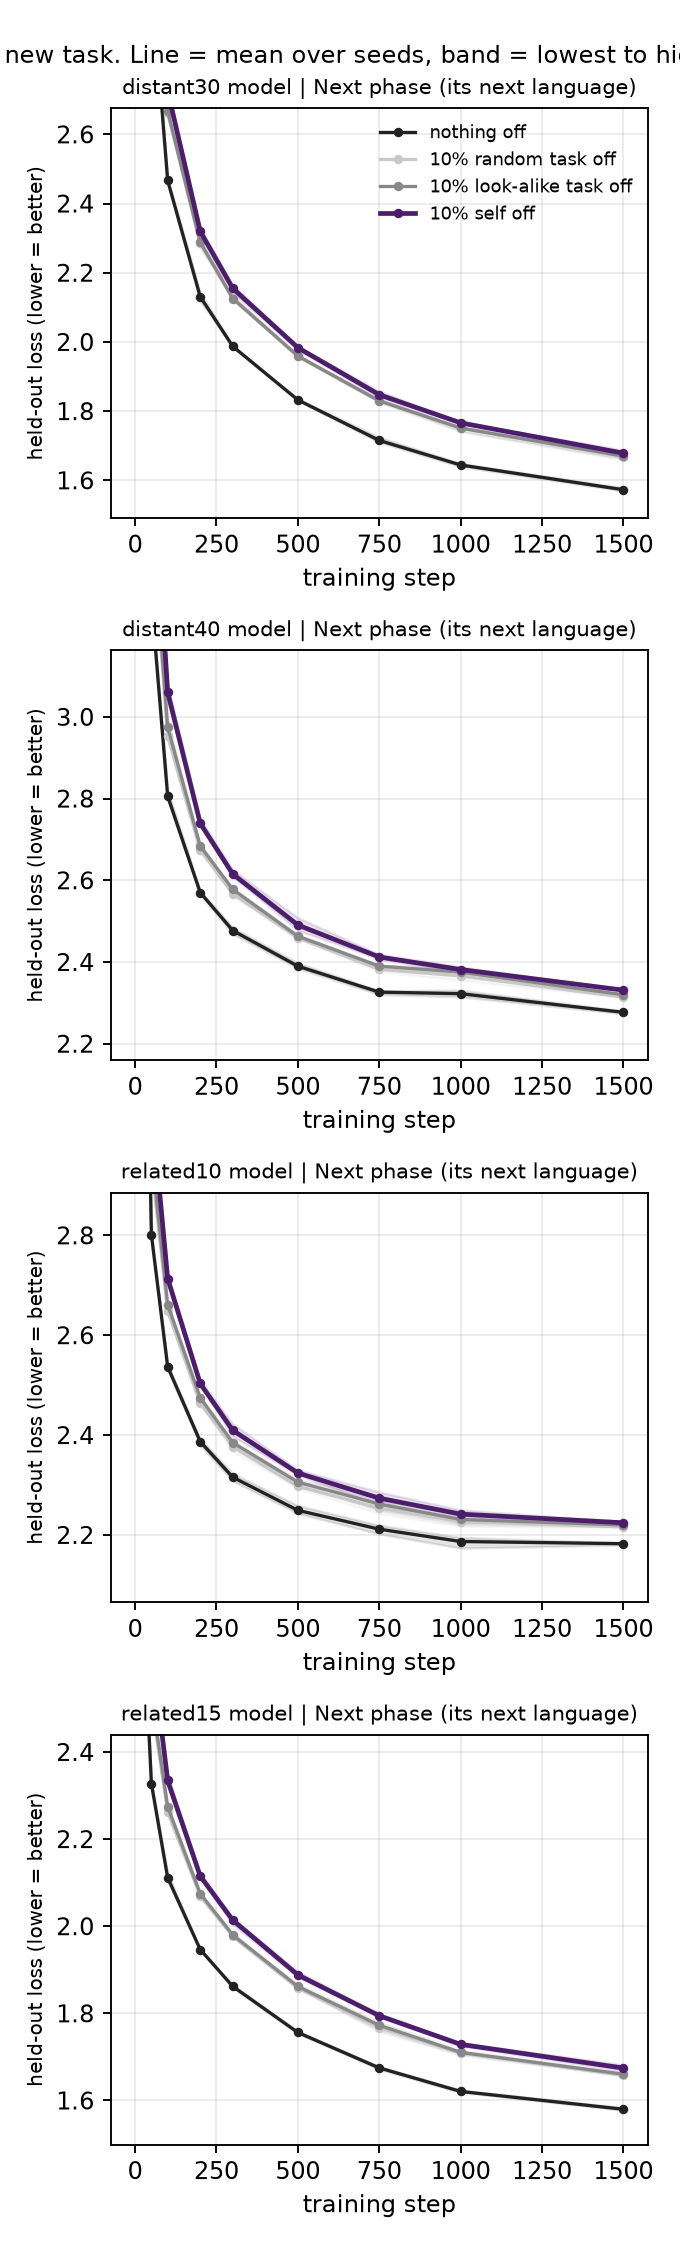

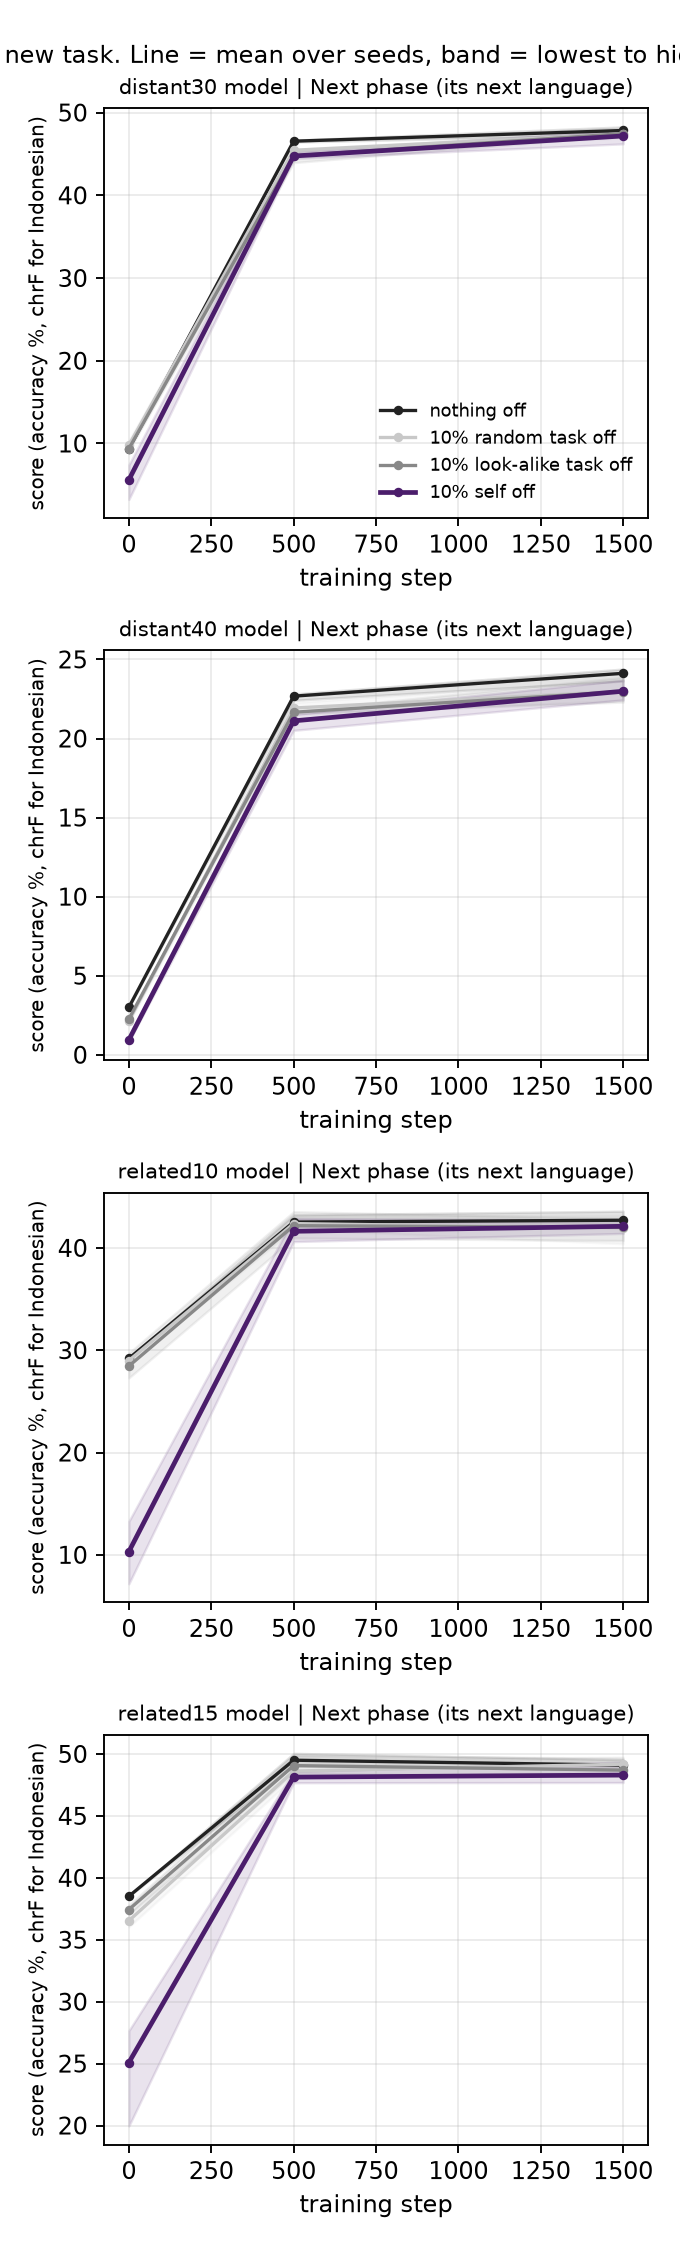

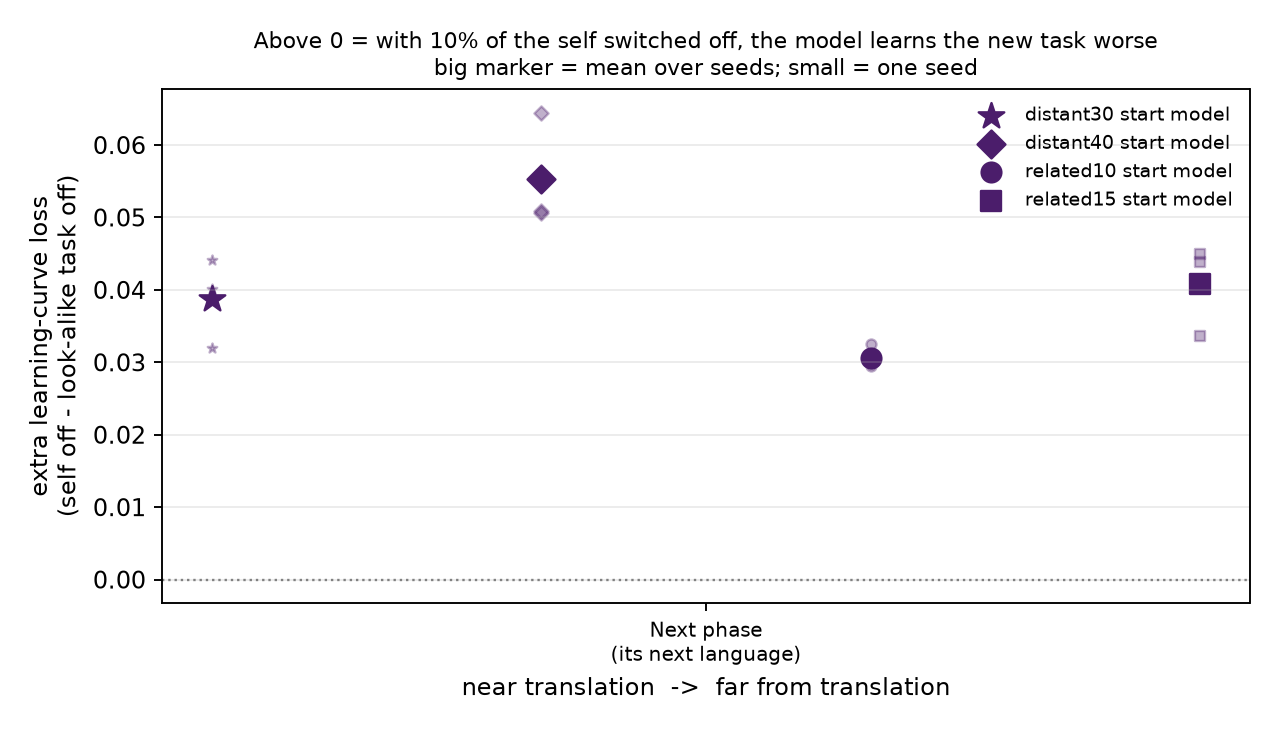

In [4]:
subprocess.run([sys.executable, "newtask_v9.py", "--summarize", "--out", "nextphase_d30"])
for f in ["fig1_learning_curves_loss.png", "fig2_learning_curves_score.png", "fig3_near_to_far.png"]:
    display(Image(f"analysis/v9/nextphase_d30/{f}"))